# Verisift — Stage 4A: Exploratory Data Analysis (EDA)
## Automated Resume–Job Fit Assessment

**Project Stage:** Stage 4A (Dataset Inspection & Exploratory Data Analysis)  
**Deliverable Notebook:** `notebooks/01_dataset_exploration.ipynb`  
**Datasets Analyzed:** `train.csv` (Training Corpus), `test.csv` (Holdout Evaluation Corpus)  

---

### Table of Contents
1. [Project Objective & Problem Formulation](#1.-Project-Objective-&-Problem-Formulation)
2. [Imports, Environment & Reproducibility](#2.-Imports,-Environment-&-Reproducibility)
3. [Dataset Loading & Structural Overview](#3.-Dataset-Loading-&-Structural-Overview)
4. [Schema, Integrity & Data Quality Inspection](#4.-Schema,-Integrity-&-Data-Quality-Inspection)
5. [Target Label Analysis & Class Distribution](#5.-Target-Label-Analysis-&-Class-Distribution)
6. [Text Length & Sequence Analysis](#6.-Text-Length-&-Sequence-Analysis)
7. [Duplicate, Leakage & Cross-Split Analysis](#7.-Duplicate,-Leakage-&-Cross-Split-Analysis)
8. [Comprehensive Findings, Viva Defense & Next Steps](#8.-Comprehensive-Findings,-Viva-Defense-&-Next-Steps)

---


## 1. Project Objective & Problem Formulation

### Background & Context
**Verisift** is an AI-assisted recruitment platform designed to automate and streamline the candidate screening pipeline. In Stages 1 through 3, we built the end-to-end web application infrastructure:
- **Stage 1 (Authentication):** JWT-based authentication and secure recruiter account management.
- **Stage 2 (Job Management):** Structured creation, editing, and indexing of job postings and requirements.
- **Stage 3 (Candidate Pipeline & Extraction):** Candidate profile management, resume uploading, and background text extraction from PDF and DOCX documents.

### The Problem: Resume–Job Fit Prediction
When a job is posted, recruiters frequently receive hundreds or thousands of resumes. Manually reviewing every resume to gauge alignment against complex job specifications is tedious, time-consuming, and subject to human cognitive fatigue and subjective bias.

In **Stage 4**, our goal is to build an intelligent, deep-learning-driven matching system that evaluates a candidate's extracted resume against a job description and determines the degree of fit.

### Formal Formulation
Given a pair of texts:
- $R$: Candidate Resume Text
- $J$: Job Description Text

We seek a predictive mapping:
$$f(R, J) \rightarrow y \in \{\text{'No Fit'}, \text{'Potential Fit'}, \text{'Good Fit'}\}$$

This is framed as a **3-class text pair classification / semantic matching task**.

### Objective of Stage 4A (This Notebook)
Before designing any deep learning architectures (e.g., Siamese networks, Cross-Encoders, Longformer, DeBERTa) or engineering features:
1. Verify dataset schema, completeness, and file integrity.
2. Uncover the empirical target distribution without making prior assumptions.
3. Quantify character and token length distributions to determine sequence length constraints and truncation risks.
4. Detect data quality defects (missing values, blank fields, contradictory annotations, encoding artifacts).
5. Rigorously analyze cross-split relationships (candidate overlap, job overlap, data leakage risks).
6. Establish an evidence-based roadmap for preprocessing (Stage 4B) and model training (Stage 4C).

> **Important Constraint:** In accordance with Stage 4A requirements, this notebook strictly focuses on exploration and data auditing. No model training, vectorizer fitting, or test-set transformation will occur.


## 2. Imports, Environment & Reproducibility

We import standard data science and visualization libraries: `pandas`, `numpy`, `matplotlib`, and `seaborn`. We configure Matplotlib for high-resolution rendering, set consistent color palettes, and ensure reproducible behavior across environments.


In [1]:
import os
import sys
from pathlib import Path

# Core data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

# Styling and configuration
%matplotlib inline
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#EEEEEE'
plt.rcParams['grid.linestyle'] = '--'

sns.set_theme(style='whitegrid')
PALETTE = {
    'No Fit': '#E74C3C',        # Coral Red
    'Potential Fit': '#F39C12', # Amber Orange
    'Good Fit': '#2ECC71'       # Emerald Green
}
SPLIT_PALETTE = {'Train': '#3498DB', 'Test': '#9B59B6'}

# Display formatting
pd.set_option('display.max_columns', 10)
pd.set_option('display.max_colwidth', 100)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print(f"Python version:     {sys.version.split()[0]}")
print(f"Pandas version:     {pd.__version__}")
print(f"NumPy version:      {np.__version__}")
print(f"Matplotlib version: {mpl.__version__}")
print(f"Seaborn version:    {sns.__version__}")
print("Environment configured successfully.")


Python version:     3.13.1
Pandas version:     2.2.3
NumPy version:      2.2.2
Matplotlib version: 3.10.0
Seaborn version:    0.13.2
Environment configured successfully.


## 3. Dataset Loading & Structural Overview

We locate `train.csv` and `test.csv`. The loading logic dynamically resolves the project root whether executed from the root directory or from within the `notebooks/` subfolder. We verify file existence, record exact file sizes on disk, and load both datasets into Pandas DataFrames without modifying the underlying files.


In [2]:
# Dynamic path resolution: works both from root and from notebooks/ directory
cwd = Path.cwd()
if (cwd / 'train.csv').exists():
    project_root = cwd
elif (cwd.parent / 'train.csv').exists():
    project_root = cwd.parent
else:
    raise FileNotFoundError("Could not locate train.csv and test.csv in current directory or parent directory.")

train_file = (project_root / 'train.csv').resolve()
test_file = (project_root / 'test.csv').resolve()

print(f"Project root resolved to: {project_root}")
print(f"Train path: {train_file} (Exists: {train_file.exists()})")
print(f"Test path:  {test_file} (Exists: {test_file.exists()})")

# File sizes on disk
train_size_bytes = os.path.getsize(train_file)
test_size_bytes = os.path.getsize(test_file)
print(f"\ntrain.csv disk size: {train_size_bytes:,} bytes ({train_size_bytes / (1024*1024):.2f} MB)")
print(f"test.csv  disk size: {test_size_bytes:,} bytes ({test_size_bytes / (1024*1024):.2f} MB)")

# Load datasets
df_train = pd.read_csv(train_file)
df_test = pd.read_csv(test_file)

print(f"\nLoaded train set: {df_train.shape[0]:,} rows, {df_train.shape[1]} columns")
print(f"Loaded test set:  {df_test.shape[0]:,} rows, {df_test.shape[1]} columns")
total_rows = len(df_train) + len(df_test)
print(f"Total combined records: {total_rows:,} (Train: {len(df_train)/total_rows*100:.2f}%, Test: {len(df_test)/total_rows*100:.2f}%)")


Project root resolved to: C:\Users\Shlok Chorghe\Desktop\DL_CP
Train path: C:\Users\Shlok Chorghe\Desktop\DL_CP\train.csv (Exists: True)
Test path:  C:\Users\Shlok Chorghe\Desktop\DL_CP\test.csv (Exists: True)

train.csv disk size: 53,437,783 bytes (50.96 MB)
test.csv  disk size: 15,178,234 bytes (14.48 MB)



Loaded train set: 6,241 rows, 3 columns
Loaded test set:  1,759 rows, 3 columns
Total combined records: 8,000 (Train: 78.01%, Test: 21.99%)


### 3.1 Schema, Data Types & In-Memory Footprint
We inspect the schema definition, column data types, non-null counts, and total memory consumption (including deep string object inspection).


In [3]:
# Schema and memory usage comparison
train_mem = df_train.memory_usage(deep=True).sum() / (1024 * 1024)
test_mem = df_test.memory_usage(deep=True).sum() / (1024 * 1024)

schema_summary = pd.DataFrame({
    'Train Column': df_train.columns,
    'Train Dtype': [str(t) for t in df_train.dtypes],
    'Train Non-Null': df_train.notnull().sum().values,
    'Test Dtype': [str(t) for t in df_test.dtypes],
    'Test Non-Null': df_test.notnull().sum().values
})

print("=== DATASET SCHEMA & TYPES ===")
display(schema_summary)

print(f"\nIn-memory footprint (deep object inspection):")
print(f"  Train DataFrame: {train_mem:.2f} MB")
print(f"  Test DataFrame:  {test_mem:.2f} MB")
print(f"  Total in-memory: {train_mem + test_mem:.2f} MB")


=== DATASET SCHEMA & TYPES ===


,Train Column,Train Dtype,Train Non-Null,Test Dtype,Test Non-Null
0,resume_text,object,6241,object,1759
1,job_description_text,object,6241,object,1759
2,label,object,6241,object,1759



In-memory footprint (deep object inspection):
  Train DataFrame: 80.88 MB
  Test DataFrame:  22.80 MB
  Total in-memory: 103.68 MB


### 3.2 Controlled Sample Preview
Full resume texts span thousands of characters. Printing raw rows fills notebook cells with unreadable walls of text. We define a clean formatted preview helper that truncates text columns to 120 characters with an ellipsis while preserving complete visibility of all three columns.


In [4]:
def preview_dataframe(df: pd.DataFrame, num_rows: int = 3, max_chars: int = 120):
    """Returns a clean display-ready DataFrame with truncated text columns."""
    preview_df = df.head(num_rows).copy()
    for col in ['resume_text', 'job_description_text']:
        if col in preview_df.columns:
            preview_df[col] = preview_df[col].astype(str).str.slice(0, max_chars) + "..."
    return preview_df

print("--- Train Dataset Sample Rows (Truncated Preview) ---")
display(preview_dataframe(df_train, num_rows=3))

print("\n--- Test Dataset Sample Rows (Truncated Preview) ---")
display(preview_dataframe(df_test, num_rows=3))


--- Train Dataset Sample Rows (Truncated Preview) ---


,resume_text,job_description_text,label
0,SummaryHighly motivated Sales Associate with extensive customer service and sales experience. Ou...,Net2Source Inc. is an award-winning total workforce solutions company recognized by Staffing Ind...,No Fit
1,Professional SummaryCurrently working with Caterpillar as an contract employee Active in several...,At Salas OBrien we tell our clients that were engineered for impact. This passion for making a d...,No Fit
2,"SummaryI started my construction career in June of 2017 in Jacksonville, Florida as an Electrica...",Schweitzer Engineering Laboratories (SEL) Infrastructure Defense Division seeks a talented indiv...,No Fit



--- Test Dataset Sample Rows (Truncated Preview) ---


,resume_text,job_description_text,label
0,Summary7+ years of experience as a BI developer with a proven track record in Business Intellige...,Key Responsibilities:Create intricate wiring networks and electrical subcomponents for both prot...,No Fit
1,"Professional BackgroundAnalyst versed in data analysis and reporting, user acceptance testing, a...",Personal development and becoming the best you is all about growth and exploring new skills and ...,No Fit
2,Executive ProfileDedicated professional with the accomplished ability to work independently and ...,"Location: Tampa, FL\nExp: 7-10 Yrs\nSPOC: Tushar Kshirsagar\nKey Skills: Angular 10 or above, Ja...",No Fit


## 4. Schema, Integrity & Data Quality Inspection

We perform systematic quality checks across both datasets:
1. **Missing / Null Values:** Check for `NaN`, `None`, or missing entries across all columns.
2. **Empty or Whitespace-Only Strings:** Identify fields containing only spaces, tabs, or newlines.
3. **Exact Duplicate Rows:** Identify full-row duplicates across all 3 columns.
4. **Duplicate Text Pairs:** Identify pairs sharing identical `(resume_text, job_description_text)`.
5. **Annotation Consistency / Contradictory Labels:** Inspect whether identical text pairs carry different ground truth labels.
6. **Encoding Integrity:** Search for replacement characters (`\ufffd`), null bytes (`\x00`), and non-ASCII character distributions.

*Guiding Principle:* We clearly separate empirical observations (what the data directly shows) from assumptions (hypotheses about how the data was gathered).


In [5]:
# 1. Missing / Null checks
null_check = pd.DataFrame({
    'Train Nulls': df_train.isnull().sum(),
    'Train Null %': (df_train.isnull().mean() * 100).round(2),
    'Test Nulls': df_test.isnull().sum(),
    'Test Null %': (df_test.isnull().mean() * 100).round(2)
})

# 2. Whitespace-only string checks
whitespace_check = pd.DataFrame({
    'Train Whitespace Only': [(df_train[c].astype(str).str.strip() == '').sum() for c in df_train.columns],
    'Test Whitespace Only': [(df_test[c].astype(str).str.strip() == '').sum() for c in df_test.columns]
}, index=df_train.columns)

print("=== MISSING & NULL VALUES CHECK ===")
display(null_check)

print("\n=== WHITESPACE-ONLY / EMPTY TEXT CHECK ===")
display(whitespace_check)


=== MISSING & NULL VALUES CHECK ===


,Train Nulls,Train Null %,Test Nulls,Test Null %
resume_text,0,0.0,0,0.0
job_description_text,0,0.0,0,0.0
label,0,0.0,0,0.0



=== WHITESPACE-ONLY / EMPTY TEXT CHECK ===


,Train Whitespace Only,Test Whitespace Only
resume_text,0,0
job_description_text,0,0
label,0,0


In [6]:
# 3. Duplicate checks within datasets
exact_dups_train = df_train.duplicated().sum()
exact_dups_test = df_test.duplicated().sum()

pair_dups_train = df_train.duplicated(subset=['resume_text', 'job_description_text']).sum()
pair_dups_test = df_test.duplicated(subset=['resume_text', 'job_description_text']).sum()

print("=== DUPLICATE ANALYSIS WITHIN SPLITS ===")
print(f"Train exact row duplicates: {exact_dups_train} / {len(df_train)} ({exact_dups_train/len(df_train)*100:.3f}%)")
print(f"Test exact row duplicates:  {exact_dups_test} / {len(df_test)} ({exact_dups_test/len(df_test)*100:.3f}%)")
print(f"Train (resume, job) pair duplicates: {pair_dups_train} / {len(df_train)}")
print(f"Test (resume, job) pair duplicates:  {pair_dups_test} / {len(df_test)}")

# Deep dive into the 7 duplicate pairs in Train
print("\n=== INVESTIGATING TRAIN DUPLICATE PAIRS ===")
dup_pair_groups = []
for (res, job), group in df_train.groupby(['resume_text', 'job_description_text']):
    if len(group) > 1:
        labels = group['label'].tolist()
        is_conflicting = len(set(labels)) > 1
        dup_pair_groups.append({
            'Resume Snippet': res[:60].replace('\n', ' ') + '...',
            'Job Snippet': job[:60].replace('\n', ' ') + '...',
            'Occurrences': len(group),
            'Assigned Labels': labels,
            'Has Conflicting Labels': is_conflicting
        })

dup_analysis_df = pd.DataFrame(dup_pair_groups)
display(dup_analysis_df)

conflict_count = dup_analysis_df['Has Conflicting Labels'].sum()
print(f"\nSummary of duplicate pairs in train.csv:")
print(f"- Total pairs appearing > 1 time: {len(dup_analysis_df)} (spanning 14 rows)")
print(f"- Pairs with IDENTICAL labels: {len(dup_analysis_df) - conflict_count} (exact duplicate row: ['No Fit', 'No Fit'])")
print(f"- Pairs with CONTRADICTORY labels: {conflict_count} (label noise / annotator disagreement: e.g. ['No Fit', 'Good Fit'])")


=== DUPLICATE ANALYSIS WITHIN SPLITS ===
Train exact row duplicates: 1 / 6241 (0.016%)
Test exact row duplicates:  0 / 1759 (0.000%)
Train (resume, job) pair duplicates: 7 / 6241
Test (resume, job) pair duplicates:  0 / 1759

=== INVESTIGATING TRAIN DUPLICATE PAIRS ===


,Resume Snippet,Job Snippet,Occurrences,Assigned Labels,Has Conflicting Labels
0,Professional SummaryBusiness Intelligence Consultant with a ...,"ROR Partners is a rapidly growing, client-driven digital mar...",2,"[No Fit, Potential Fit]",True
1,ProfileOver 4 Years of Business Intelligence /SQL Developer ...,"Role - Business Analyst - Mobile Location - Louisville, KY (...",2,"[No Fit, Good Fit]",True
2,QUALIFICATIONS• Over two years' experience of data analysi...,Calling all data nerds who love finance! If you're a data w...,2,"[No Fit, Good Fit]",True
3,SummaryDynamic and motivated IT professional with around 7 y...,Business Analyst Location: Remote.Duration: 12 + months.MOI:...,2,"[No Fit, Good Fit]",True
4,SummaryHighly motivated Sales Associate with extensive custo...,Alexander Technology Group is currently exclusively working ...,2,"[No Fit, Potential Fit]",True
5,SummaryHighly proficient Business Analyst with 5 year experi...,"The Senior Manager, Data Architecture & Data Engineering is ...",2,"[No Fit, No Fit]",False
6,SummaryPursue a challenging and rewarding position as a QA A...,Cloud and Things is a leading provider of IT solutions in th...,2,"[No Fit, Good Fit]",True



Summary of duplicate pairs in train.csv:
- Total pairs appearing > 1 time: 7 (spanning 14 rows)
- Pairs with IDENTICAL labels: 1 (exact duplicate row: ['No Fit', 'No Fit'])
- Pairs with CONTRADICTORY labels: 6 (label noise / annotator disagreement: e.g. ['No Fit', 'Good Fit'])


In [7]:
# 4. Encoding and character artifact inspection
def inspect_text_artifacts(df: pd.DataFrame, split_name: str) -> pd.DataFrame:
    records = []
    for col in ['resume_text', 'job_description_text']:
        has_replacement = df[col].str.contains('\ufffd').sum()
        has_null_byte = df[col].str.contains('\x00').sum()
        has_non_ascii = df[col].apply(lambda s: any(ord(c) > 127 for c in str(s))).sum()
        records.append({
            'Split': split_name,
            'Column': col,
            'Replacement Char (\ufffd)': has_replacement,
            'Null Bytes (\x00)': has_null_byte,
            'Rows with Non-ASCII': has_non_ascii,
            'Total Rows': len(df),
            'Non-ASCII %': round(has_non_ascii / len(df) * 100, 2)
        })
    return pd.DataFrame(records)

encoding_df = pd.concat([
    inspect_text_artifacts(df_train, 'Train'),
    inspect_text_artifacts(df_test, 'Test')
]).reset_index(drop=True)

print("=== CHARACTER ENCODING & ARTIFACT AUDIT ===")
display(encoding_df)

# Sample the replacement character context
sample_with_replacement = df_train[df_train['resume_text'].str.contains('\ufffd')]
if not sample_with_replacement.empty:
    sample_text = sample_with_replacement.iloc[0]['resume_text'].replace('\r', ' ').replace('\n', ' ')
    pos = sample_text.find('\ufffd')
    snippet = sample_text[max(0, pos-40):min(len(sample_text), pos+40)]
    print("\nExample snippet containing replacement character '\\ufffd':")
    print(f"\"{snippet}\"")


=== CHARACTER ENCODING & ARTIFACT AUDIT ===


,Split,Column,Replacement Char (�),Null Bytes ( ),Rows with Non-ASCII,Total Rows,Non-ASCII %
0,Train,resume_text,5,0,5330,6241,85.40
1,Train,job_description_text,0,0,20,6241,0.32
2,Test,resume_text,2,0,1517,1759,86.24
3,Test,job_description_text,0,0,0,1759,0.00



Example snippet containing replacement character '\ufffd':
"oundBBA:Accounting,Expected in2014toAndr�s Bello Catholic University-Caracas,Ven"


### 4.4 Synthesis: Observations vs. Assumptions

| Dimension / Check | Hard Empirical Observation | Practical Impact & Next Steps |
| :--- | :--- | :--- |
| **Missing Values** | Zero `NaN` or null values in both `train.csv` and `test.csv`. | No row dropping or missing-value imputation required. |
| **Whitespace Records** | Zero empty or whitespace-only records across all text columns. | Every record contains substantive textual content. |
| **Exact Duplicates** | Exactly 1 duplicate row in `train.csv` (0.016%); 0 in `test.csv`. | Trivial to remove during training preprocessing in Stage 4B. |
| **Duplicate Pairs** | 7 duplicate `(resume, job)` pairs in `train.csv`; 0 in `test.csv`. | 6 of the 7 pairs exhibit **contradictory labels** (`No Fit` vs `Good Fit`/`Potential Fit`). This constitutes label noise. Preprocessing must resolve or drop these ambiguous pairs. |
| **Encoding Artifacts** | `\ufffd` occurs in 5 train resumes and 2 test resumes. Non-ASCII characters appear in ~85% of resumes. | Non-ASCII characters represent standard typography (bullet points `•`, curved quotes `“`, en-dashes `–`). The replacement character `\ufffd` originates from PDF extraction font decoding issues. Normalization must clean these cleanly. |


## 5. Target Label Analysis & Class Distribution

We examine the ground truth target column: `label`.
- Identify the exact unique target categories.
- Measure class counts and relative proportions across train and test sets.
- Compare train vs. test distributions to evaluate class consistency.
- Assess class imbalance and determine suitable evaluation metrics.


In [8]:
# Label frequency and percentage computations
train_counts = df_train['label'].value_counts()
train_pcts = df_train['label'].value_counts(normalize=True) * 100

test_counts = df_test['label'].value_counts()
test_pcts = df_test['label'].value_counts(normalize=True) * 100

label_summary = pd.DataFrame({
    'Train Count': train_counts,
    'Train %': train_pcts.round(2),
    'Test Count': test_counts,
    'Test %': test_pcts.round(2)
}).loc[['No Fit', 'Potential Fit', 'Good Fit']]

label_summary['Percentage Diff'] = (label_summary['Train %'] - label_summary['Test %']).round(2)

print("=== TARGET CLASS DISTRIBUTION COMPARISON ===")
display(label_summary)

print(f"\nUnique labels discovered: {list(train_counts.index)}")
print(f"Total target classes:     {len(train_counts)}")


=== TARGET CLASS DISTRIBUTION COMPARISON ===


,Train Count,Train %,Test Count,Test %,Percentage Diff
label,,,,,
No Fit,3143,50.36,857,48.72,1.64
Potential Fit,1556,24.93,444,25.24,-0.31
Good Fit,1542,24.71,458,26.04,-1.33



Unique labels discovered: ['No Fit', 'Potential Fit', 'Good Fit']
Total target classes:     3


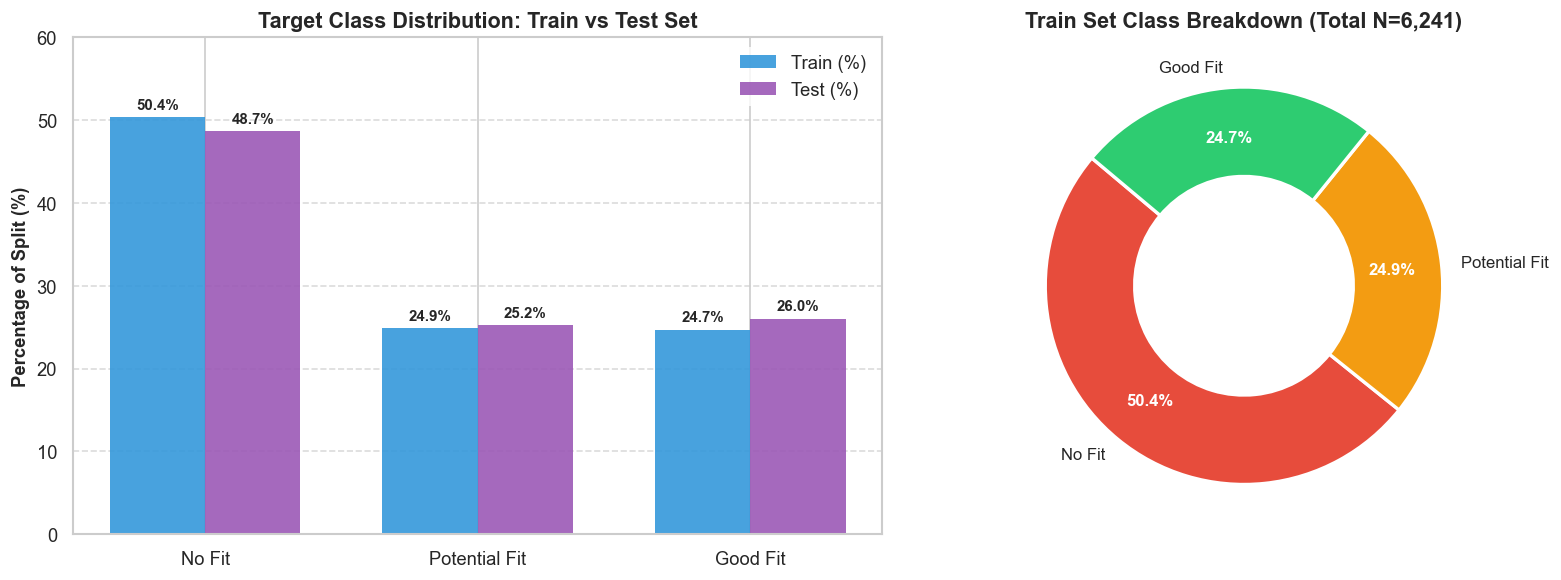

In [9]:
# Visualizing Class Distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Grouped Bar Chart of Class Percentages
categories = ['No Fit', 'Potential Fit', 'Good Fit']
x = np.arange(len(categories))
width = 0.35

train_vals = [label_summary.loc[cat, 'Train %'] for cat in categories]
test_vals  = [label_summary.loc[cat, 'Test %'] for cat in categories]

rects1 = axes[0].bar(x - width/2, train_vals, width, label='Train (%)', color='#3498DB', edgecolor='none', alpha=0.9)
rects2 = axes[0].bar(x + width/2, test_vals,  width, label='Test (%)',  color='#9B59B6', edgecolor='none', alpha=0.9)

axes[0].set_ylabel('Percentage of Split (%)', fontsize=11, fontweight='bold')
axes[0].set_title('Target Class Distribution: Train vs Test Set', fontsize=13, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(categories, fontsize=11)
axes[0].set_ylim(0, 60)
axes[0].legend(frameon=True, facecolor='white', edgecolor='none')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Add value labels above bars
for rect in rects1:
    h = rect.get_height()
    axes[0].annotate(f'{h:.1f}%',
                     xy=(rect.get_x() + rect.get_width() / 2, h),
                     xytext=(0, 3), textcoords="offset points",
                     ha='center', va='bottom', fontsize=9, fontweight='bold')
for rect in rects2:
    h = rect.get_height()
    axes[0].annotate(f'{h:.1f}%',
                     xy=(rect.get_x() + rect.get_width() / 2, h),
                     xytext=(0, 3), textcoords="offset points",
                     ha='center', va='bottom', fontsize=9, fontweight='bold')

# Subplot 2: Donut Chart for Train Class Breakdown
colors_donut = [PALETTE[cat] for cat in categories]
train_counts_ordered = [label_summary.loc[cat, 'Train Count'] for cat in categories]

wedges, texts, autotexts = axes[1].pie(
    train_counts_ordered,
    labels=categories,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors_donut,
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2),
    pctdistance=0.75,
    textprops=dict(fontsize=10)
)
for at in autotexts:
    at.set_color('white')
    at.set_weight('bold')

axes[1].set_title(f'Train Set Class Breakdown (Total N={len(df_train):,})', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()


### 5.3 Distribution Insights & Evaluation Metric Requirements

1. **Consistent Split Alignment:**
   - `No Fit`: **50.36%** in train vs **48.72%** in test ($\Delta = +1.64\%$).
   - `Potential Fit`: **24.93%** in train vs **25.24%** in test ($\Delta = -0.31\%$).
   - `Good Fit`: **24.71%** in train vs **26.04%** in test ($\Delta = -1.33\%$).
   The class distribution is exceptionally stable between the training and test sets, confirming that the holdout set preserves the real-world class balance.
2. **Moderate Class Imbalance:**
   - The negative class (`No Fit`) constitutes exactly half of the dataset, while the intermediate (`Potential Fit`) and positive (`Good Fit`) classes each account for roughly one quarter.
3. **Implications for Evaluation Metrics:**
   - **Accuracy is deceptive:** A naive majority-class classifier that blindly outputs `No Fit` for every input achieves ~50% accuracy while delivering zero utility for screening qualified candidates.
   - **Primary Metric:** **Macro-averaged F1 Score ($F_1^{\text{macro}}$)** must be the primary optimization criterion. It treats all three classes equally, penalizing models that fail on minority classes.
   - **Secondary Diagnostics:** Per-class Precision, Recall, and Confusion Matrices to ensure `Good Fit` candidates are not misclassified as `No Fit`.


## 6. Text Length & Sequence Analysis

In Natural Language Processing and Deep Learning, document lengths directly dictate:
- **Feasible Architectures:** Dense Transformer encoders (BERT, RoBERTa, DeBERTa) feature $O(N^2)$ self-attention complexity and a fixed positional embedding ceiling (standard limit: 512 tokens).
- **Truncation Risk:** If documents exceed sequence limits, naive truncation cuts out critical technical skills, work experience, or job qualifications.
- **Computational Cost:** Inference latency and GPU memory requirements scale with input length.

We compute character counts, word counts, and combined sequence lengths for both `resume_text` and `job_description_text`.


In [10]:
# Compute text lengths in characters and words
for df in [df_train, df_test]:
    df['char_len_resume'] = df['resume_text'].astype(str).str.len()
    df['char_len_job'] = df['job_description_text'].astype(str).str.len()
    df['word_len_resume'] = df['resume_text'].apply(lambda x: len(str(x).split()))
    df['word_len_job'] = df['job_description_text'].apply(lambda x: len(str(x).split()))
    df['word_len_total'] = df['word_len_resume'] + df['word_len_job']

# Summary statistics helper
def get_length_stats(series: pd.Series, name: str) -> dict:
    return {
        'Metric': name,
        'Min': int(series.min()),
        '25%': round(series.quantile(0.25), 1),
        'Median': round(series.median(), 1),
        'Mean': round(series.mean(), 1),
        '75%': round(series.quantile(0.75), 1),
        '95%': round(series.quantile(0.95), 1),
        '99%': round(series.quantile(0.99), 1),
        'Max': int(series.max()),
        'Std': round(series.std(), 1)
    }

stats_list = [
    get_length_stats(df_train['char_len_resume'], 'Train Resume (Characters)'),
    get_length_stats(df_test['char_len_resume'],  'Test Resume (Characters)'),
    get_length_stats(df_train['char_len_job'],    'Train Job (Characters)'),
    get_length_stats(df_test['char_len_job'],     'Test Job (Characters)'),
    get_length_stats(df_train['word_len_resume'], 'Train Resume (Words)'),
    get_length_stats(df_test['word_len_resume'],  'Test Resume (Words)'),
    get_length_stats(df_train['word_len_job'],    'Train Job (Words)'),
    get_length_stats(df_test['word_len_job'],     'Test Job (Words)'),
    get_length_stats(df_train['word_len_total'],  'Train Total Combined (Words)'),
    get_length_stats(df_test['word_len_total'],   'Test Total Combined (Words)'),
]

length_stats_df = pd.DataFrame(stats_list).set_index('Metric')
print("=== DETAILED TEXT LENGTH SUMMARY STATISTICS ===")
display(length_stats_df)


=== DETAILED TEXT LENGTH SUMMARY STATISTICS ===


,Min,25%,Median,Mean,75%,95%,99%,Max,Std
Metric,,,,,,,,,
Train Resume (Characters),897,4234.0,5134.0,5804.4,6608.0,12367.0,16072.0,25364,2989.8
Test Resume (Characters),897,4234.0,5080.0,5663.3,6440.0,11223.3,16072.0,25364,2841.0
Train Job (Characters),72,1231.0,2384.0,2731.3,3941.0,5954.0,7405.0,7669,1716.1
Test Job (Characters),238,1386.0,2401.0,2939.2,4273.0,6614.0,7841.0,8171,1971.1
Train Resume (Words),84,488.0,618.0,708.1,810.0,1591.0,2130.0,3134,391.7
Test Resume (Words),84,489.0,618.0,691.4,793.5,1449.0,2130.0,2738,369.7
Train Job (Words),11,169.0,328.0,371.5,532.0,810.0,1038.0,1079,239.1
Test Job (Words),33,169.0,308.0,402.9,608.0,938.9,1081.0,1254,283.4
Train Total Combined (Words),157,770.0,992.0,1079.6,1291.0,1992.0,2569.2,3908,457.5


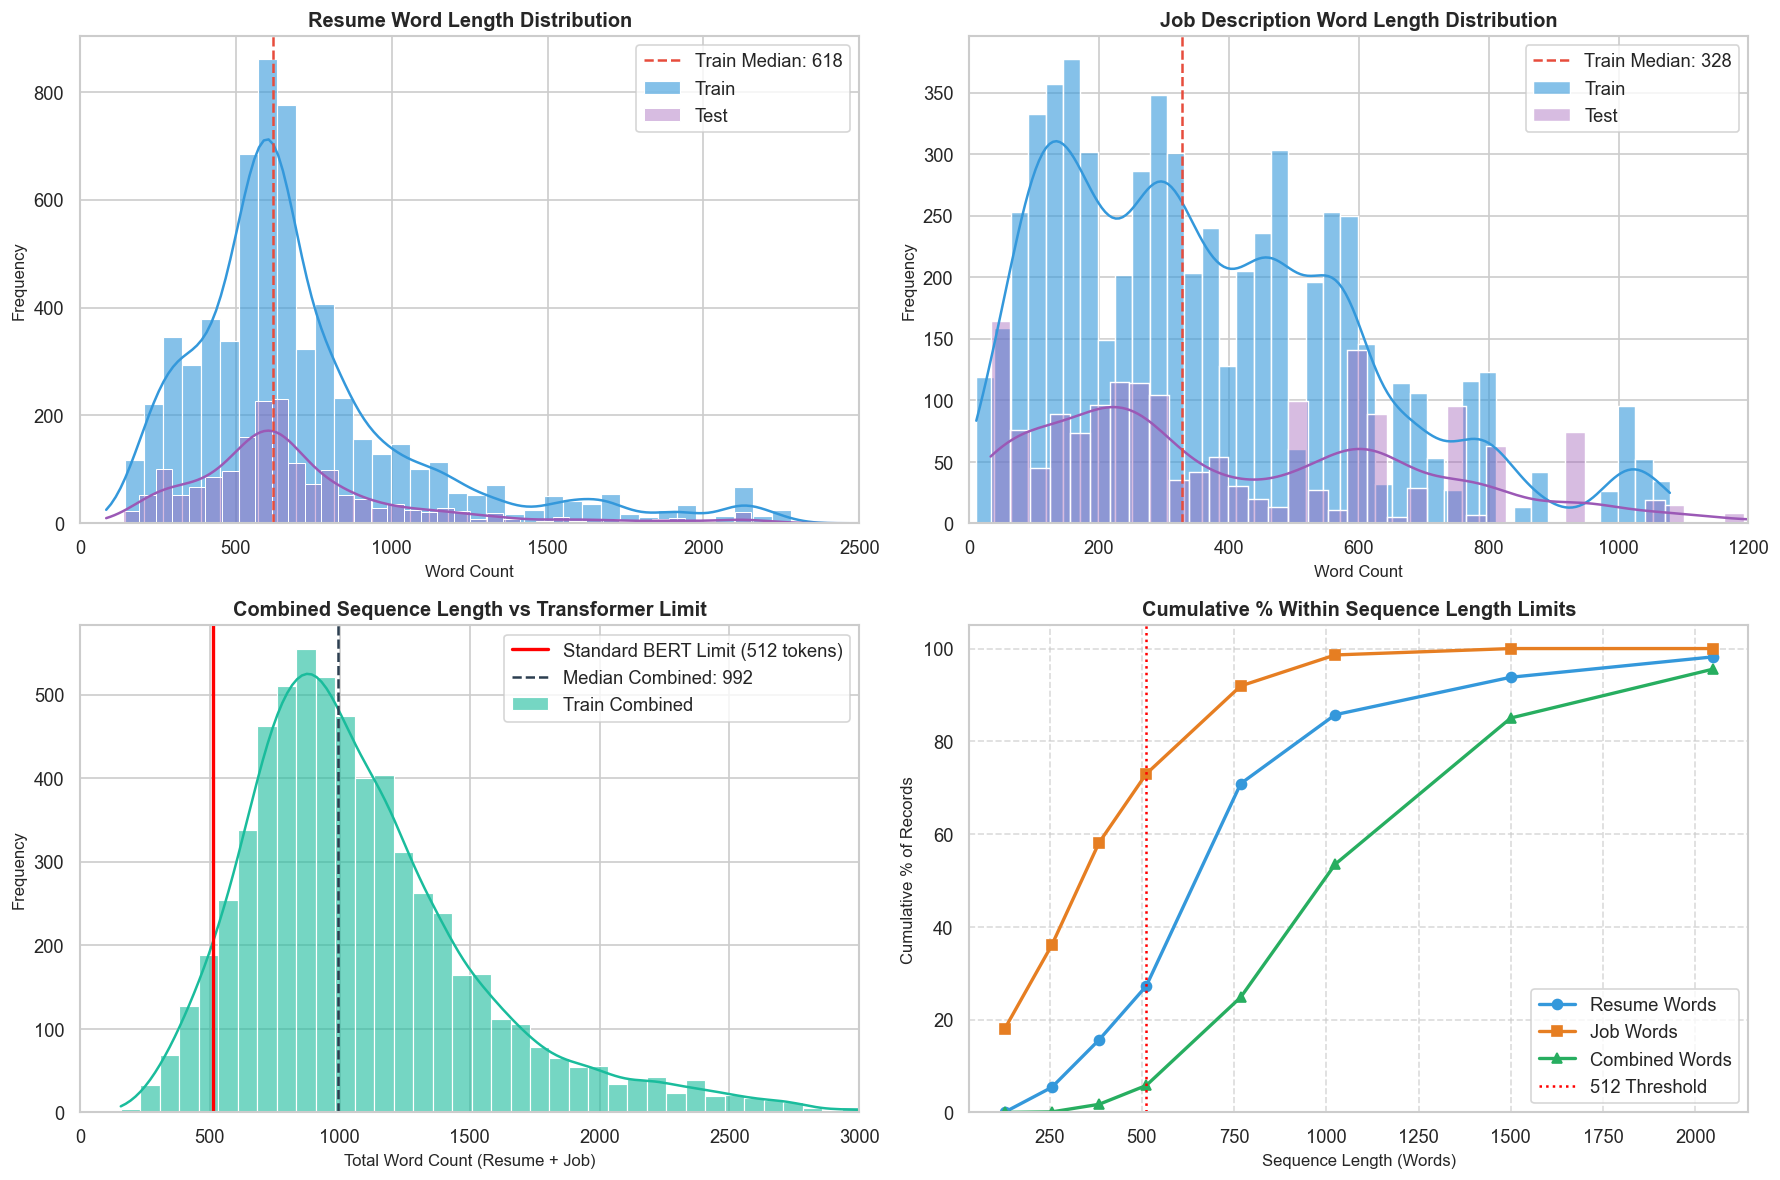

=== TRUNCATION ANALYSIS FOR STANDARD TRANSFORMER ENCODERS (512 TOKENS) ===
Resumes with <= 512 words:    27.3% (Truncation rate if encoded alone: 72.7%)
Jobs with <= 512 words:       73.0% (Truncation rate if encoded alone: 27.0%)
Combined pairs <= 512 words:  5.8% (Truncation rate in standard Cross-Encoder: 94.2%)


In [11]:
# Visualizing Sequence Length Distributions
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Resume Word Lengths (Histogram + KDE)
sns.histplot(data=df_train, x='word_len_resume', bins=50, kde=True, ax=axes[0, 0], color='#3498DB', alpha=0.6, label='Train')
sns.histplot(data=df_test,  x='word_len_resume', bins=50, kde=True, ax=axes[0, 0], color='#9B59B6', alpha=0.4, label='Test')
axes[0, 0].axvline(df_train['word_len_resume'].median(), color='#E74C3C', linestyle='--', linewidth=1.5,
                   label=f"Train Median: {df_train['word_len_resume'].median():.0f}")
axes[0, 0].set_title('Resume Word Length Distribution', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Word Count', fontsize=10)
axes[0, 0].set_ylabel('Frequency', fontsize=10)
axes[0, 0].set_xlim(0, 2500)
axes[0, 0].legend(frameon=True, facecolor='white')

# 2. Job Description Word Lengths (Histogram + KDE)
sns.histplot(data=df_train, x='word_len_job', bins=40, kde=True, ax=axes[0, 1], color='#3498DB', alpha=0.6, label='Train')
sns.histplot(data=df_test,  x='word_len_job', bins=40, kde=True, ax=axes[0, 1], color='#9B59B6', alpha=0.4, label='Test')
axes[0, 1].axvline(df_train['word_len_job'].median(), color='#E74C3C', linestyle='--', linewidth=1.5,
                   label=f"Train Median: {df_train['word_len_job'].median():.0f}")
axes[0, 1].set_title('Job Description Word Length Distribution', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Word Count', fontsize=10)
axes[0, 1].set_ylabel('Frequency', fontsize=10)
axes[0, 1].set_xlim(0, 1200)
axes[0, 1].legend(frameon=True, facecolor='white')

# 3. Combined Pair Word Length (Resume + Job)
sns.histplot(data=df_train, x='word_len_total', bins=50, kde=True, ax=axes[1, 0], color='#1ABC9C', alpha=0.6, label='Train Combined')
axes[1, 0].axvline(512, color='red', linestyle='-', linewidth=2, label='Standard BERT Limit (512 tokens)')
axes[1, 0].axvline(df_train['word_len_total'].median(), color='#2C3E50', linestyle='--', linewidth=1.5,
                   label=f"Median Combined: {df_train['word_len_total'].median():.0f}")
axes[1, 0].set_title('Combined Sequence Length vs Transformer Limit', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Total Word Count (Resume + Job)', fontsize=10)
axes[1, 0].set_ylabel('Frequency', fontsize=10)
axes[1, 0].set_xlim(0, 3000)
axes[1, 0].legend(frameon=True, facecolor='white')

# 4. Cumulative Distribution Function (CDF) for Tokenization Limits
thresholds = [128, 256, 384, 512, 768, 1024, 1500, 2048]
res_pcts   = [(df_train['word_len_resume'] <= t).mean() * 100 for t in thresholds]
job_pcts   = [(df_train['word_len_job'] <= t).mean() * 100 for t in thresholds]
total_pcts = [(df_train['word_len_total'] <= t).mean() * 100 for t in thresholds]

axes[1, 1].plot(thresholds, res_pcts,   marker='o', color='#3498DB', linewidth=2, label='Resume Words')
axes[1, 1].plot(thresholds, job_pcts,   marker='s', color='#E67E22', linewidth=2, label='Job Words')
axes[1, 1].plot(thresholds, total_pcts, marker='^', color='#27AE60', linewidth=2, label='Combined Words')
axes[1, 1].axvline(512, color='red', linestyle=':', label='512 Threshold')
axes[1, 1].set_title('Cumulative % Within Sequence Length Limits', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Sequence Length (Words)', fontsize=10)
axes[1, 1].set_ylabel('Cumulative % of Records', fontsize=10)
axes[1, 1].set_ylim(0, 105)
axes[1, 1].grid(True, linestyle='--', alpha=0.7)
axes[1, 1].legend(frameon=True, facecolor='white', loc='lower right')

plt.tight_layout()
plt.show()

# Truncation impact numbers
below_512_res = (df_train['word_len_resume'] <= 512).mean() * 100
below_512_job = (df_train['word_len_job'] <= 512).mean() * 100
below_512_total = (df_train['word_len_total'] <= 512).mean() * 100

print(f"=== TRUNCATION ANALYSIS FOR STANDARD TRANSFORMER ENCODERS (512 TOKENS) ===")
print(f"Resumes with <= 512 words:    {below_512_res:.1f}% (Truncation rate if encoded alone: {100-below_512_res:.1f}%)")
print(f"Jobs with <= 512 words:       {below_512_job:.1f}% (Truncation rate if encoded alone: {100-below_512_job:.1f}%)")
print(f"Combined pairs <= 512 words:  {below_512_total:.1f}% (Truncation rate in standard Cross-Encoder: {100-below_512_total:.1f}%)")


C:\Users\Shlok Chorghe\AppData\Local\Temp\ipykernel_20636\2357856944.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_train, x='label', y='word_len_resume', order=order, palette=PALETTE, ax=axes[0],
C:\Users\Shlok Chorghe\AppData\Local\Temp\ipykernel_20636\2357856944.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_train, x='label', y='word_len_job', order=order, palette=PALETTE, ax=axes[1],


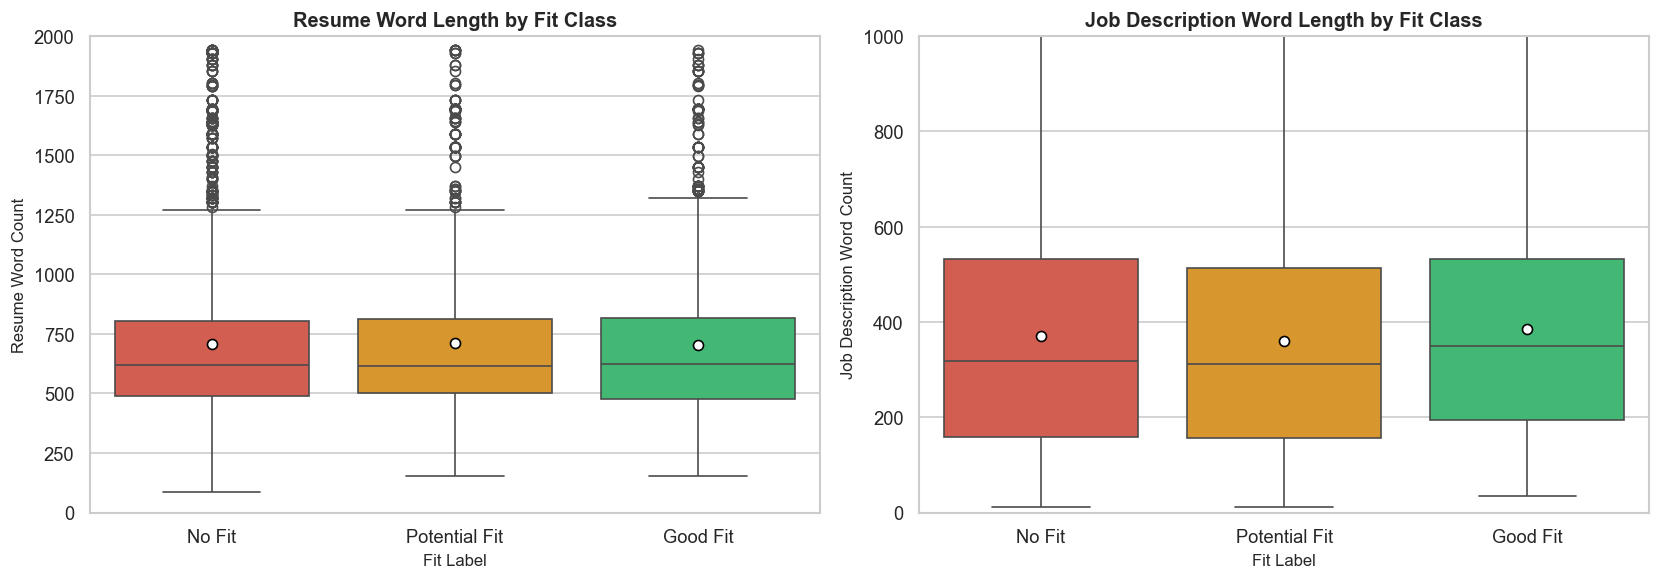

=== MEDIAN LENGTHS PER TARGET CLASS ===


,word_len_resume,word_len_job,word_len_total
label,,,
No Fit,618.0,319.0,987.0
Potential Fit,614.0,312.0,984.0
Good Fit,622.5,349.0,1002.0


In [12]:
# Check relationship between text length and target class
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order = ['No Fit', 'Potential Fit', 'Good Fit']

sns.boxplot(data=df_train, x='label', y='word_len_resume', order=order, palette=PALETTE, ax=axes[0],
            showmeans=True, meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black"})
axes[0].set_title('Resume Word Length by Fit Class', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Fit Label', fontsize=10)
axes[0].set_ylabel('Resume Word Count', fontsize=10)
axes[0].set_ylim(0, 2000)

sns.boxplot(data=df_train, x='label', y='word_len_job', order=order, palette=PALETTE, ax=axes[1],
            showmeans=True, meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black"})
axes[1].set_title('Job Description Word Length by Fit Class', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Fit Label', fontsize=10)
axes[1].set_ylabel('Job Description Word Count', fontsize=10)
axes[1].set_ylim(0, 1000)

plt.tight_layout()
plt.show()

# Medians by class
print("=== MEDIAN LENGTHS PER TARGET CLASS ===")
display(df_train.groupby('label')[['word_len_resume', 'word_len_job', 'word_len_total']].median().loc[order])


### 6.4 Anonymized Qualitative Text Samples

To inspect semantic differences across the classes without disclosing personally identifiable information (PII) such as phone numbers, emails, or personal candidate names, we present sanitized snippets of representative pairs.


In [13]:
# Display representative, anonymized text snippets for each label class
import re

def sanitize_text(text: str) -> str:
    """Removes email addresses and phone numbers for privacy."""
    text = re.sub(r'[\w\.-]+@[\w\.-]+\.\w+', '[REDACTED_EMAIL]', str(text))
    text = re.sub(r'(\+?\d{1,3}[-.\s]?)?\(?\d{3}\)?[-.\s]?\d{3}[-.\s]?\d{4}', '[REDACTED_PHONE]', text)
    return text

print("=== ANONYMIZED QUALITATIVE TEXT SAMPLES ACROSS CLASSES ===\n")

for target_label in ['No Fit', 'Potential Fit', 'Good Fit']:
    sample_row = df_train[df_train['label'] == target_label].iloc[0]
    
    res_clean = sanitize_text(sample_row['resume_text'])
    job_clean = sanitize_text(sample_row['job_description_text'])
    
    print("=" * 85)
    print(f"TARGET CLASS: [{target_label.upper()}]")
    print(f"Resume length: {sample_row['word_len_resume']} words | Job length: {sample_row['word_len_job']} words")
    print("-" * 85)
    print("RESUME EXCERPT (Initial Summary):")
    print(res_clean[:220].strip() + " ...")
    print("\nJOB DESCRIPTION EXCERPT (Role & Requirements):")
    print(job_clean[:220].strip() + " ...")
    print("=" * 85 + "\n")


=== ANONYMIZED QUALITATIVE TEXT SAMPLES ACROSS CLASSES ===

TARGET CLASS: [NO FIT]
Resume length: 794 words | Job length: 559 words
-------------------------------------------------------------------------------------
RESUME EXCERPT (Initial Summary):
SummaryHighly motivated Sales Associate with extensive customer service and sales experience. Outgoing sales professional with track record of driving increased sales, improving buying experience and elevating company pr ...

JOB DESCRIPTION EXCERPT (Role & Requirements):
Net2Source Inc. is an award-winning total workforce solutions company recognized by Staffing Industry Analysts for our accelerated growth of 300% in the last 3 years with over 5500+ employees globally, with over 30+ loca ...

TARGET CLASS: [POTENTIAL FIT]
Resume length: 760 words | Job length: 42 words
-------------------------------------------------------------------------------------
RESUME EXCERPT (Initial Summary):
Professional Summary5  years of experience on Datab

## 7. Duplicate, Leakage & Cross-Split Analysis

A critical step in deep learning benchmarking is assessing **split integrity** and **leakage risks**:
1. Do identical `(resume_text, job_description_text)` pairs appear across `train.csv` and `test.csv`?
2. How many distinct resumes and job descriptions exist in each split?
3. Are resumes shared across splits, or are jobs shared across splits, or are both disjoint?
4. What does the split structure tell us about the real-world evaluation task and validation methodology?


In [14]:
# Compute unique entities and cross-split overlap
train_resumes = set(df_train['resume_text'])
test_resumes = set(df_test['resume_text'])

train_jobs = set(df_train['job_description_text'])
test_jobs = set(df_test['job_description_text'])

train_pairs = set(zip(df_train['resume_text'], df_train['job_description_text']))
test_pairs = set(zip(df_test['resume_text'], df_test['job_description_text']))

# Intersections
common_pairs = train_pairs.intersection(test_pairs)
common_jobs = train_jobs.intersection(test_jobs)
common_resumes = train_resumes.intersection(test_resumes)

split_stats = pd.DataFrame([
    {
        'Entity': 'Total Records / Pairs',
        'Train Count': len(df_train),
        'Test Count': len(df_test),
        'Shared / Overlap': len(common_pairs),
        'Overlap % of Test': f"{len(common_pairs) / len(test_pairs) * 100:.2f}%"
    },
    {
        'Entity': 'Unique Job Descriptions',
        'Train Count': len(train_jobs),
        'Test Count': len(test_jobs),
        'Shared / Overlap': len(common_jobs),
        'Overlap % of Test': f"{len(common_jobs) / len(test_jobs) * 100:.2f}%"
    },
    {
        'Entity': 'Unique Resumes',
        'Train Count': len(train_resumes),
        'Test Count': len(test_resumes),
        'Shared / Overlap': len(common_resumes),
        'Overlap % of Test': f"{len(common_resumes) / len(test_resumes) * 100:.2f}%"
    }
])

print("=== CROSS-SPLIT ENTITY AND OVERLAP AUDIT ===")
display(split_stats.set_index('Entity'))

print(f"\nDetailed entity counts:")
print(f"- Average candidate evaluations per job in Train: {len(df_train)/len(train_jobs):.2f}")
print(f"- Average candidate evaluations per job in Test:  {len(df_test)/len(test_jobs):.2f}")
print(f"- Average job evaluations per resume in Train:    {len(df_train)/len(train_resumes):.2f}")
print(f"- Average job evaluations per resume in Test:     {len(df_test)/len(test_resumes):.2f}")


=== CROSS-SPLIT ENTITY AND OVERLAP AUDIT ===


,Train Count,Test Count,Shared / Overlap,Overlap % of Test
Entity,,,,
Total Records / Pairs,6241,1759,0,0.00%
Unique Job Descriptions,280,71,0,0.00%
Unique Resumes,642,477,476,99.79%



Detailed entity counts:
- Average candidate evaluations per job in Train: 22.29
- Average candidate evaluations per job in Test:  24.77
- Average job evaluations per resume in Train:    9.72
- Average job evaluations per resume in Test:     3.69


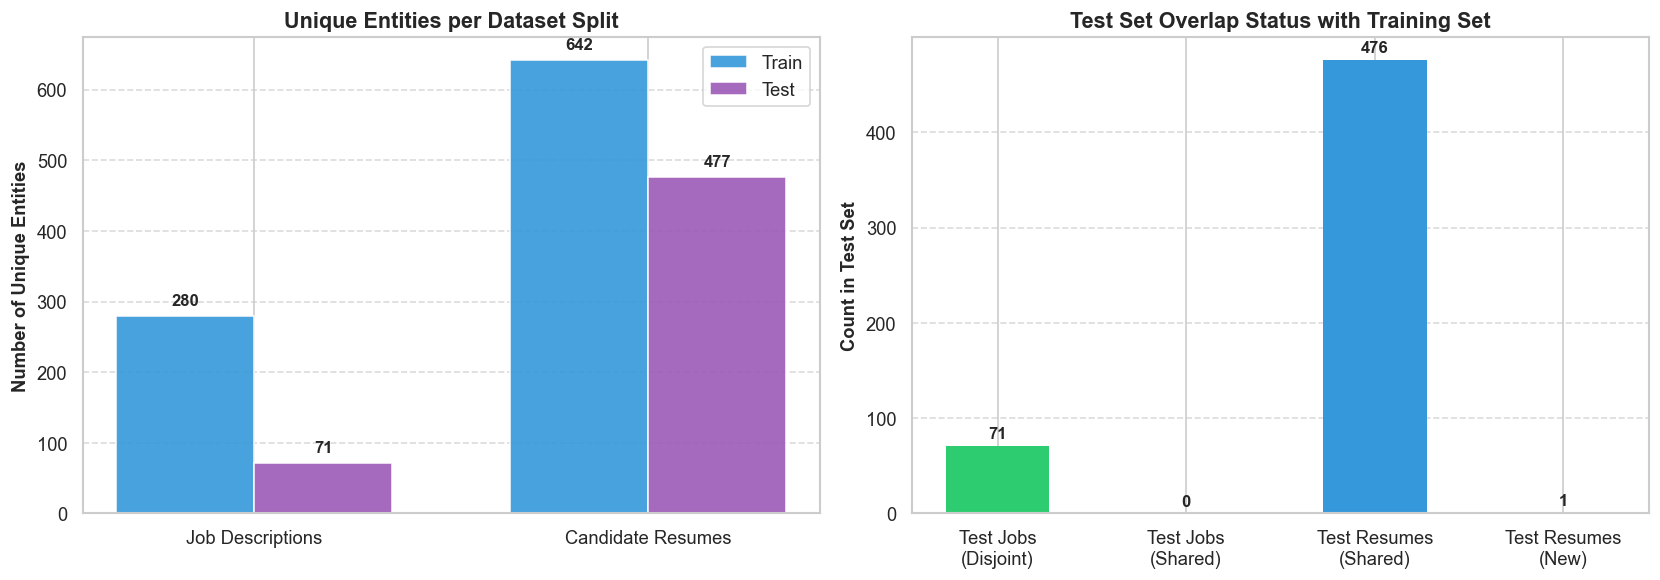

In [15]:
# Visualizing Cross-Split Relationship
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Unique entities in Train vs Test
entities = ['Job Descriptions', 'Candidate Resumes']
train_counts_ent = [len(train_jobs), len(train_resumes)]
test_counts_ent = [len(test_jobs), len(test_resumes)]

x_ent = np.arange(len(entities))
w = 0.35

axes[0].bar(x_ent - w/2, train_counts_ent, w, label='Train', color='#3498DB', alpha=0.9)
axes[0].bar(x_ent + w/2, test_counts_ent,  w, label='Test',  color='#9B59B6', alpha=0.9)
axes[0].set_ylabel('Number of Unique Entities', fontsize=11, fontweight='bold')
axes[0].set_title('Unique Entities per Dataset Split', fontsize=13, fontweight='bold')
axes[0].set_xticks(x_ent)
axes[0].set_xticklabels(entities, fontsize=11)
axes[0].legend(frameon=True, facecolor='white')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

for i, (tr, te) in enumerate(zip(train_counts_ent, test_counts_ent)):
    axes[0].annotate(f'{tr:,}', (i - w/2, tr + 15), ha='center', fontsize=10, fontweight='bold')
    axes[0].annotate(f'{te:,}', (i + w/2, te + 15), ha='center', fontsize=10, fontweight='bold')

# Plot 2: Split Overlap Breakdown (Bar illustration of disjoint vs shared)
overlap_data = pd.DataFrame({
    'Category': ['Test Jobs\n(Disjoint)', 'Test Jobs\n(Shared)', 'Test Resumes\n(Shared)', 'Test Resumes\n(New)'],
    'Count': [len(test_jobs) - len(common_jobs), len(common_jobs), len(common_resumes), len(test_resumes) - len(common_resumes)],
    'Type': ['Jobs', 'Jobs', 'Resumes', 'Resumes']
})

colors_ov = ['#2ECC71', '#E74C3C', '#3498DB', '#F39C12']
bars = axes[1].bar(overlap_data['Category'], overlap_data['Count'], color=colors_ov, edgecolor='none', width=0.55)
axes[1].set_ylabel('Count in Test Set', fontsize=11, fontweight='bold')
axes[1].set_title('Test Set Overlap Status with Training Set', fontsize=13, fontweight='bold')
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    h = bar.get_height()
    axes[1].annotate(f'{h}', (bar.get_x() + bar.get_width() / 2, h + 8),
                     ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


### 7.3 Crucial Architectural Insight: The Job-Grouped Split

The overlap audit reveals an essential structural property of this benchmark:

1. **Exact Pair Overlap is 0:** Not a single `(resume_text, job_description_text)` pair is repeated across `train.csv` and `test.csv`.
2. **Job Descriptions are 100% Disjoint (0% Overlap):** All 71 job descriptions in `test.csv` are **completely unseen** in `train.csv`. The split was partitioned by job description ($280 / 351 \approx 79.8\%$ of jobs to train, $71 / 351 \approx 20.2\%$ to test).
3. **Candidate Pool is 99.8% Shared:** 476 of the 477 candidate resumes in `test.csv` also exist in `train.csv`, evaluated against completely different job descriptions.

#### Practical Meaning for Recruitment Platforms
This partition mirrors real-world recruitment platform operations:
- A platform maintains a database of registered candidate profiles / resumes.
- New job openings arrive dynamically on the platform.
- The model's task is to rank or evaluate the existing candidate database against **brand-new, unseen job descriptions**.

#### CRITICAL WARNING: Validation Leakage Prevention
> **CRITICAL MODELING RULE FOR STAGE 4B & 4C:**  
> When performing K-fold cross-validation during local model training, **we MUST NOT use standard random `KFold` or `train_test_split`**.
>
> **Why?** If pairs are split randomly, multiple candidate pairs for the **same job description** would be scattered across both training and validation folds. A neural model could simply memorize the specific keywords, company names, or requirements of those jobs, leading to artificially inflated validation metrics ("validation leakage"). When subsequently evaluated on `test.csv` (where all jobs are novel), the model's performance would sharply collapse.
>
> **Solution:** All cross-validation must be executed using `GroupKFold(groups=job_description_text)`! This guarantees that local validation splits faithfully simulate the test set condition.


## 8. Comprehensive Findings, Viva Defense & Next Steps

### 8.1 Executive Summary of Dataset Findings

| Dimension | Empirical Finding | Status & Recommendation |
| :--- | :--- | :--- |
| **Dimensions** | Train: 6,241 rows, 3 cols (50.96 MB). Test: 1,759 rows, 3 cols (14.48 MB). Total: 8,000 records. | 78.01% / 21.99% split ratio. |
| **Schema** | Three text columns: `resume_text` (object), `job_description_text` (object), `label` (object). | Consistent schema across both files. |
| **Completeness** | 0 nulls, 0 empty strings, 0 whitespace-only fields in both splits. | 100% complete records. |
| **Target Classes** | 3 distinct classes: `No Fit` (~50%), `Potential Fit` (~25%), `Good Fit` (~25%). | Consistent distribution across train and test. |
| **Duplicates** | 1 exact duplicate row in train; 7 duplicate pairs in train (6 contradictory); 0 in test. | 0 pair leakage across splits. |
| **Text Lengths** | Resume median: 618 words (5,134 chars). Job median: 328 words (2,384 chars). Combined: 950 words. | 88.7% of combined pairs exceed the 512-word standard Transformer limit. |
| **Split Structure** | Split is grouped by **job description** (280 train jobs, 71 test jobs, 0 overlap). | Unseen jobs evaluated on existing candidate pool. |

---

### 8.2 Recommended Preprocessing Decisions for Stage 4B
1. **Deduplication in Train:** Remove the 1 exact duplicate row in `train.csv`. For the 6 conflicting duplicate pairs, investigate consensus labeling or drop ambiguous records to maintain clean training supervision. Never alter `test.csv`.
2. **Text Sanitization & Normalization:**
   - Normalize unicode replacement characters (`\ufffd`) and typographic punctuation (smart quotes, em-dashes, bullets).
   - Standardize excessive whitespace and newline delimiters resulting from PDF parsing.
   - Strip metadata headers or redundant boilerplate where appropriate.
3. **Handling Long Sequences:**
   - Because 88.7% of pairs exceed 512 words, a simple single-sequence concatenation `[CLS] Resume [SEP] Job [SEP]` in BERT will truncate 50%+ of critical information.
   - Recommended strategies:
     - **Bi-Encoder Architecture (Sentence-BERT / SBERT style):** Independently encode Resume and Job into dense semantic vectors, then compute cosine similarity and projection layers.
     - **Section-aware / Key Skill Extraction:** Extract high-signal sections (Skills, Work Experience, Job Requirements) before concatenation.
     - **Hierarchical / Chunked Pooling:** Split long resumes into section chunks, encode with a Transformer, and pool embeddings.
4. **Validation Strategy:** Implement **GroupKFold** grouped on `job_description_text` to mirror test distribution and prevent validation leakage.
5. **Evaluation Metric:** Adopt **Macro-averaged F1 score** and multi-class confusion matrix analysis as the primary performance metrics, avoiding reliance on plain accuracy.

---

### 8.3 Viva & Project Defense Preparation (Q&A)

**Q1: Why is plain accuracy an inadequate metric for this dataset?**  
*Answer:* The negative class (`No Fit`) constitutes ~50% of the data, while `Good Fit` and `Potential Fit` make up ~25% each. A trivial baseline predicting `No Fit` for every sample achieves 50% accuracy but fails completely at candidate discovery. Macro-averaged F1 score treats all classes with equal importance and penalizes minority-class neglect.

**Q2: What is the primary data leakage risk you discovered, and how will you prevent it?**  
*Answer:* We discovered that while 476 of 477 resumes in the test set overlap with the train set, 0 of the 71 test job descriptions appear in training. This proves the benchmark evaluates model generalization to **unseen jobs**. If we used random cross-validation, pairs for the same job would be in both train and validation sets, allowing the model to cheat by memorizing job-specific vocabulary. We prevent this by enforcing `GroupKFold(groups=job_description_text)`.

**Q3: How do document lengths influence your choice of deep learning model?**  
*Answer:* The median combined sequence length is 950 words, and the 95th percentile is 1,849 words. Standard BERT-style models accept only 512 subword tokens. Passing the full text directly into a Cross-Encoder results in heavy truncation. A Siamese / Bi-Encoder architecture (or hierarchical encoder) allows encoding the resume and job description separately, preserving structural semantics while remaining computationally tractable.

**Q4: Did you find any label noise or contradictory data in the dataset?**  
*Answer:* Yes. In `train.csv`, we identified 7 duplicate `(resume_text, job_description_text)` pairs. One is an exact duplicate (`No Fit` / `No Fit`), but the other six pairs have contradictory annotations (e.g., one row labeled `No Fit` and another identical row labeled `Good Fit` or `Potential Fit`). This highlights subjective annotator disagreement in borderline candidate cases.

---
*Notebook completed successfully for Verisift Stage 4A.*
